#                                              PRCP-1020-HousePricePred

# PTID-CDS-APR-23-1491

. Nagashree K

. Niharika T

. Meghashree K

. KM Bindushree

. Jaishree rawat

# PROBLEM STATEMENT
Task 1:- Prepare a complete data analysis report on the given data.

Task 2:-a) Create a robust machine learning algorithm to accurately predict the price of the house given the various factors across the market.      
            b) Determine the relationship between the house features and how the price varies based on this.

Task3:- Come up with suggestions for the customer to buy the house according to the area, price and other requirements.

In [1]:
# import basic libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
import warnings
warnings.filterwarnings('ignore')

In [2]:
# load data
data=pd.read_csv('data.csv')
data

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125


## Basic checks

Here I check a subset of data by the head method and check if there is any missing data using the info method. 

In [3]:
#check the num of rows and columns
data.shape

(1460, 81)

In [4]:
#print first 5 rows n columns
data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [5]:
#print last 5 rows n columns
data.tail()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
1455,1456,60,RL,62.0,7917,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,175000
1456,1457,20,RL,85.0,13175,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,2,2010,WD,Normal,210000
1457,1458,70,RL,66.0,9042,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,Shed,2500,5,2010,WD,Normal,266500
1458,1459,20,RL,68.0,9717,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2010,WD,Normal,142125
1459,1460,20,RL,75.0,9937,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,6,2008,WD,Normal,147500


In [6]:
data.head(pd.set_option('display.max_rows',None))

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000
5,6,50,RL,85.0,14115,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,Shed,700,10,2009,WD,Normal,143000
6,7,20,RL,75.0,10084,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,8,2007,WD,Normal,307000
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
8,9,50,RM,51.0,6120,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,4,2008,WD,Abnorml,129900
9,10,190,RL,50.0,7420,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,1,2008,WD,Normal,118000


In [7]:
#print columns
data.columns

Index(['Id', 'MSSubClass', 'MSZoning', 'LotFrontage', 'LotArea', 'Street',
       'Alley', 'LotShape', 'LandContour', 'Utilities', 'LotConfig',
       'LandSlope', 'Neighborhood', 'Condition1', 'Condition2', 'BldgType',
       'HouseStyle', 'OverallQual', 'OverallCond', 'YearBuilt', 'YearRemodAdd',
       'RoofStyle', 'RoofMatl', 'Exterior1st', 'Exterior2nd', 'MasVnrType',
       'MasVnrArea', 'ExterQual', 'ExterCond', 'Foundation', 'BsmtQual',
       'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinSF1',
       'BsmtFinType2', 'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', 'Heating',
       'HeatingQC', 'CentralAir', 'Electrical', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'KitchenQual',
       'TotRmsAbvGrd', 'Functional', 'Fireplaces', 'FireplaceQu', 'GarageType',
       'GarageYrBlt', 'GarageFinish', 'GarageCars', 'GarageArea', 'GarageQual',
       'GarageCond', 'PavedDrive

In [8]:
#check for datatypes
data.dtypes

Id                 int64
MSSubClass         int64
MSZoning          object
LotFrontage      float64
LotArea            int64
Street            object
Alley             object
LotShape          object
LandContour       object
Utilities         object
LotConfig         object
LandSlope         object
Neighborhood      object
Condition1        object
Condition2        object
BldgType          object
HouseStyle        object
OverallQual        int64
OverallCond        int64
YearBuilt          int64
YearRemodAdd       int64
RoofStyle         object
RoofMatl          object
Exterior1st       object
Exterior2nd       object
MasVnrType        object
MasVnrArea       float64
ExterQual         object
ExterCond         object
Foundation        object
BsmtQual          object
BsmtCond          object
BsmtExposure      object
BsmtFinType1      object
BsmtFinSF1         int64
BsmtFinType2      object
BsmtFinSF2         int64
BsmtUnfSF          int64
TotalBsmtSF        int64
Heating           object


In [9]:
#check info
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [10]:
#statistical analysis
data.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [11]:
#check for null values
data.isnull().sum(pd.set_option('display.max_rows',None))

Id                  0
MSSubClass          0
MSZoning            0
LotFrontage       259
LotArea             0
Street              0
Alley            1369
LotShape            0
LandContour         0
Utilities           0
LotConfig           0
LandSlope           0
Neighborhood        0
Condition1          0
Condition2          0
BldgType            0
HouseStyle          0
OverallQual         0
OverallCond         0
YearBuilt           0
YearRemodAdd        0
RoofStyle           0
RoofMatl            0
Exterior1st         0
Exterior2nd         0
MasVnrType          8
MasVnrArea          8
ExterQual           0
ExterCond           0
Foundation          0
BsmtQual           37
BsmtCond           37
BsmtExposure       38
BsmtFinType1       37
BsmtFinSF1          0
BsmtFinType2       38
BsmtFinSF2          0
BsmtUnfSF           0
TotalBsmtSF         0
Heating             0
HeatingQC           0
CentralAir          0
Electrical          1
1stFlrSF            0
2ndFlrSF            0
LowQualFin

## Data Preprocessing

In [12]:
data.isnull().sum()/len(data)*100

Id                0.000000
MSSubClass        0.000000
MSZoning          0.000000
LotFrontage      17.739726
LotArea           0.000000
Street            0.000000
Alley            93.767123
LotShape          0.000000
LandContour       0.000000
Utilities         0.000000
LotConfig         0.000000
LandSlope         0.000000
Neighborhood      0.000000
Condition1        0.000000
Condition2        0.000000
BldgType          0.000000
HouseStyle        0.000000
OverallQual       0.000000
OverallCond       0.000000
YearBuilt         0.000000
YearRemodAdd      0.000000
RoofStyle         0.000000
RoofMatl          0.000000
Exterior1st       0.000000
Exterior2nd       0.000000
MasVnrType        0.547945
MasVnrArea        0.547945
ExterQual         0.000000
ExterCond         0.000000
Foundation        0.000000
BsmtQual          2.534247
BsmtCond          2.534247
BsmtExposure      2.602740
BsmtFinType1      2.534247
BsmtFinSF1        0.000000
BsmtFinType2      2.602740
BsmtFinSF2        0.000000
B

In [13]:
#we are handling only features which have less than 50% missing values

<AxesSubplot:>

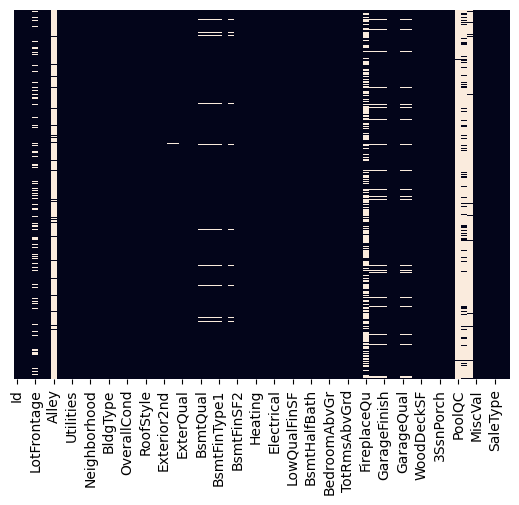

In [14]:
sns.heatmap(data.isnull(),yticklabels=False,cbar=False)

In [15]:
num_columns=data.select_dtypes(exclude='O').columns
num_columns

Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')

In [16]:
cat_columns=data.select_dtypes(include='O').columns
cat_columns                              

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='object')

## Handling missing values in LotFrontage  

In [17]:
data.loc[data['LotFrontage'].isnull()==True]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
7,8,60,RL,NaN,10382,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,350,11,2009,WD,Normal,200000
12,13,20,RL,NaN,12968,Pave,NaN,IR2,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,144000
14,15,20,RL,NaN,10920,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,GdWo,NaN,0,5,2008,WD,Normal,157000
16,17,20,RL,NaN,11241,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,Shed,700,3,2010,WD,Normal,149000
24,25,20,RL,NaN,8246,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,5,2010,WD,Normal,154000
31,32,20,RL,NaN,8544,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,6,2008,WD,Normal,149350
42,43,85,RL,NaN,9180,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,12,2007,WD,Normal,144000
43,44,20,RL,NaN,9200,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,MnPrv,NaN,0,7,2008,WD,Normal,130250
50,51,60,RL,NaN,13869,Pave,NaN,IR2,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2007,WD,Normal,177000
64,65,60,RL,NaN,9375,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,GdPrv,NaN,0,2,2009,WD,Normal,219500


<AxesSubplot:xlabel='LotFrontage', ylabel='Count'>

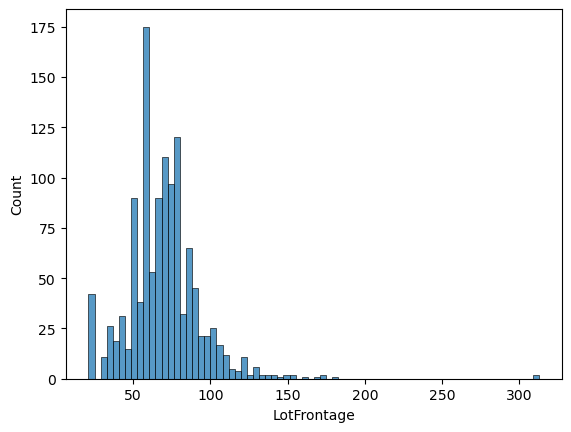

In [18]:
sns.histplot(x='LotFrontage',data=data)

In [19]:
data['LotFrontage'].median()

69.0

In [20]:
data.loc[data['LotFrontage'].isnull()==True,'LotFrontage']=69

In [21]:
data.loc[data['LotFrontage'].isnull()==True]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


## Handling missing values in BsmtQual

<AxesSubplot:xlabel='BsmtQual', ylabel='count'>

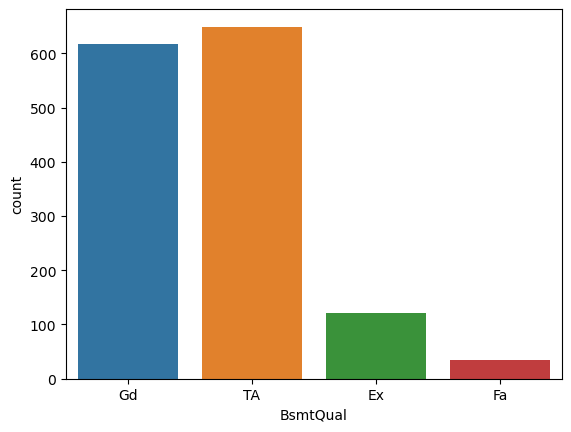

In [22]:
sns.countplot(x='BsmtQual',data=data)

In [23]:
data.value_counts('BsmtQual')

BsmtQual
TA    649
Gd    618
Ex    121
Fa     35
dtype: int64

In [24]:
data.loc[data['BsmtQual'].isnull()==True,'BsmtQual']='TA'

In [25]:
data.loc[data['BsmtQual'].isnull()==True]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


## Handling missing values in BsmtCond

<AxesSubplot:xlabel='BsmtCond', ylabel='count'>

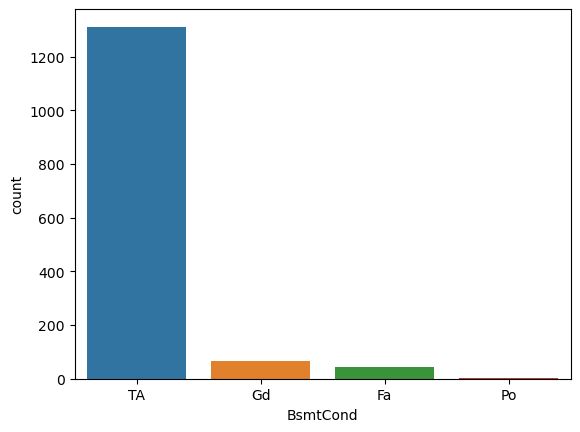

In [26]:
sns.countplot(data=data,x='BsmtCond')

In [27]:
data.value_counts('BsmtCond')

BsmtCond
TA    1311
Gd      65
Fa      45
Po       2
dtype: int64

In [28]:
data['BsmtCond'].mode()

0    TA
Name: BsmtCond, dtype: object

In [29]:
data.loc[data['BsmtCond'].isnull()==True,'BsmtCond']='TA'

In [30]:
data.loc[data['BsmtCond'].isnull()==True]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


## Handling missing values in MasVnrType

<AxesSubplot:xlabel='MasVnrType', ylabel='count'>

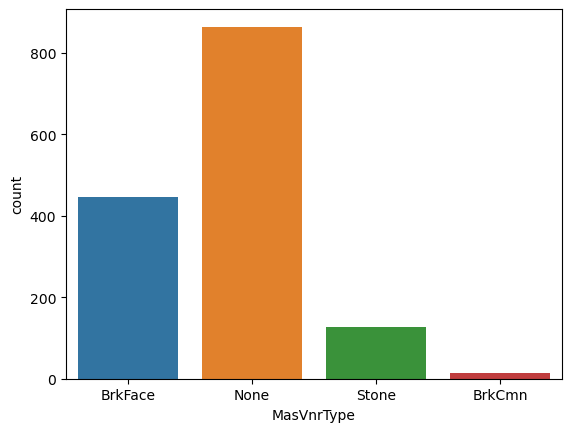

In [31]:
sns.countplot(data=data,x='MasVnrType')

In [32]:
data.value_counts('MasVnrType')

MasVnrType
None       864
BrkFace    445
Stone      128
BrkCmn      15
dtype: int64

In [33]:
data['MasVnrType'].mode()

0    None
Name: MasVnrType, dtype: object

In [34]:
data.loc[data['MasVnrType'].isnull()==True,'MasVnrType']='None'

In [35]:
data.loc[data['MasVnrType'].isnull()==True]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


## Handling missing values in MasVnrArea

<AxesSubplot:xlabel='MasVnrArea', ylabel='Count'>

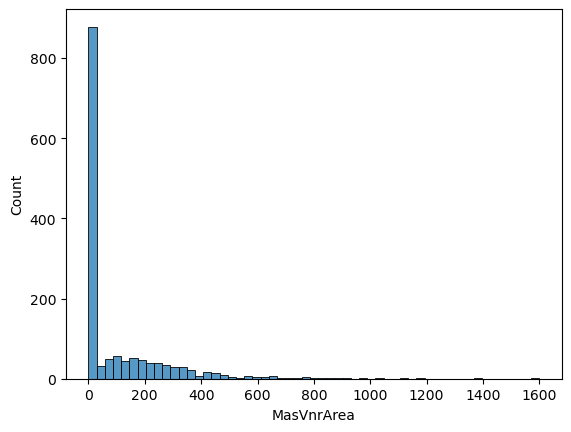

In [36]:
sns.histplot(data=data,x='MasVnrArea')

In [37]:
data['MasVnrArea'].median()

0.0

In [38]:
data.loc[data['MasVnrArea'].isnull()==True,'MasVnrArea']=0

In [39]:
data.loc[data['MasVnrArea'].isnull()==True]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


## Handling missing values in BsmtExposure

<AxesSubplot:xlabel='BsmtExposure', ylabel='count'>

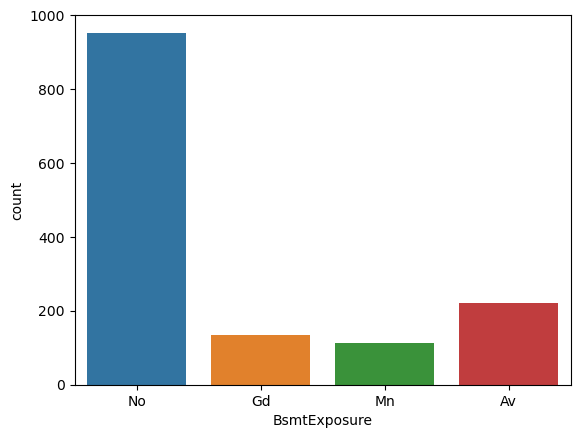

In [40]:
sns.countplot(data=data,x='BsmtExposure')

In [41]:
data['BsmtExposure'].mode()

0    No
Name: BsmtExposure, dtype: object

In [42]:
data.loc[data['BsmtExposure'].isnull()==True,'BsmtExposure']='No'

In [43]:
data.loc[data['BsmtExposure'].isnull()==True]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


## Handling missing values in BsmtFinType1

<AxesSubplot:xlabel='BsmtFinType1', ylabel='count'>

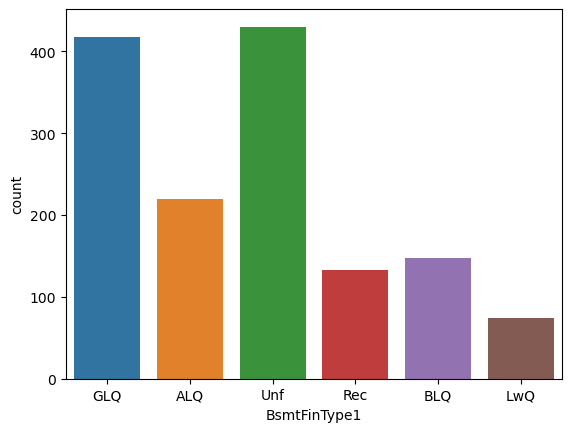

In [44]:
sns.countplot(data=data,x='BsmtFinType1')

In [45]:
data['BsmtFinType1'].mode()

0    Unf
Name: BsmtFinType1, dtype: object

In [46]:
data.loc[data['BsmtFinType1'].isnull()==True,'BsmtFinType1']='Unf'

In [47]:
data.loc[data['BsmtFinType1'].isnull()==True]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


## Handling missing values in BsmtFinType2

<AxesSubplot:xlabel='BsmtFinType2', ylabel='count'>

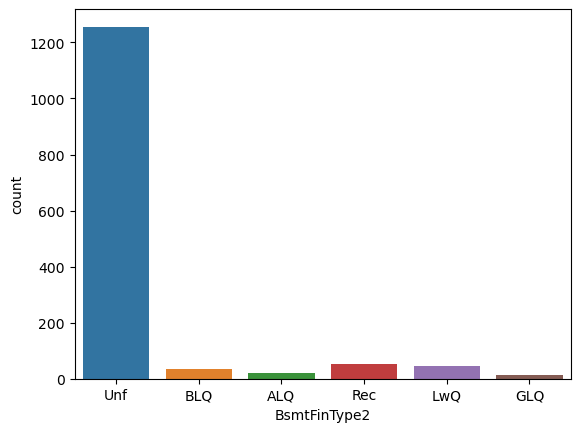

In [48]:
sns.countplot(data=data,x='BsmtFinType2')

In [49]:
data['BsmtFinType2'].mode()

0    Unf
Name: BsmtFinType2, dtype: object

In [50]:
data.loc[data['BsmtFinType2'].isnull()==True,'BsmtFinType2']='Unf'

In [51]:
data.loc[data['BsmtFinType1'].isnull()==True]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


## Handling missing values in FireplaceQu

<AxesSubplot:xlabel='FireplaceQu', ylabel='count'>

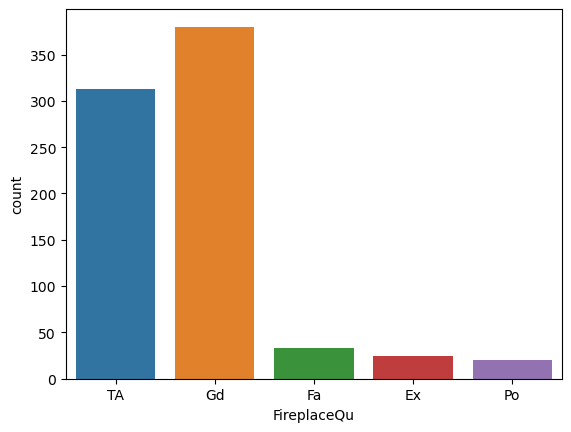

In [52]:
sns.countplot(data=data,x='FireplaceQu')

In [53]:
data['FireplaceQu'].mode()

0    Gd
Name: FireplaceQu, dtype: object

In [54]:
data.loc[data['FireplaceQu'].isnull()==True,'FireplaceQu']='Gd'

In [55]:
data.loc[data['FireplaceQu'].isnull()==True]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [56]:
## Handling missing values in GarageType

<AxesSubplot:xlabel='GarageType', ylabel='count'>

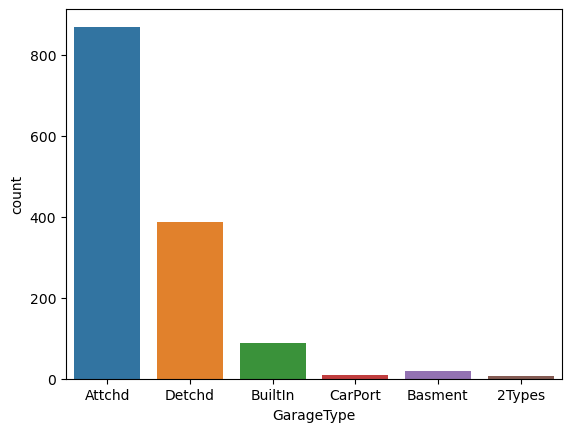

In [57]:
sns.countplot(data=data,x='GarageType')

In [58]:
data['GarageType'].mode()

0    Attchd
Name: GarageType, dtype: object

In [59]:
data.loc[data['GarageType'].isnull()==True,'GarageType']='Attchd'

In [60]:
data.loc[data['GarageType'].isnull()==True]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [61]:
## Handling missing values in GarageFinish

<AxesSubplot:xlabel='GarageFinish', ylabel='count'>

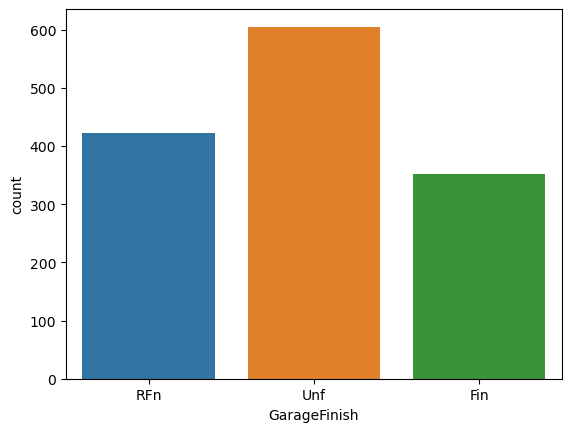

In [62]:
sns.countplot(data=data,x='GarageFinish')

In [63]:
data['GarageFinish'].mode()

0    Unf
Name: GarageFinish, dtype: object

In [64]:
data.loc[data['GarageFinish'].isnull()==True,'GarageFinish']='Unf'

In [65]:
data.loc[data['GarageFinish'].isnull()==True]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [66]:
## Handling missing values in GarageQual

<AxesSubplot:xlabel='GarageQual', ylabel='count'>

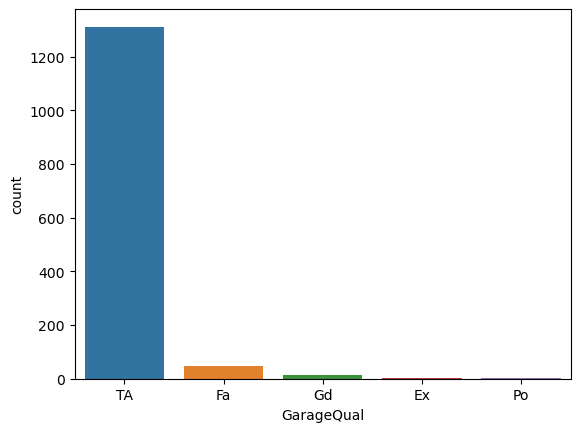

In [67]:
sns.countplot(data=data,x='GarageQual')

In [68]:
data['GarageQual'].mode()

0    TA
Name: GarageQual, dtype: object

In [69]:
data.loc[data['GarageQual'].isnull()==True,'GarageQual']='TA'

In [70]:
data.loc[data['GarageQual'].isnull()==True]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [71]:
## Handling missing values in GarageCond

<AxesSubplot:xlabel='GarageCond', ylabel='count'>

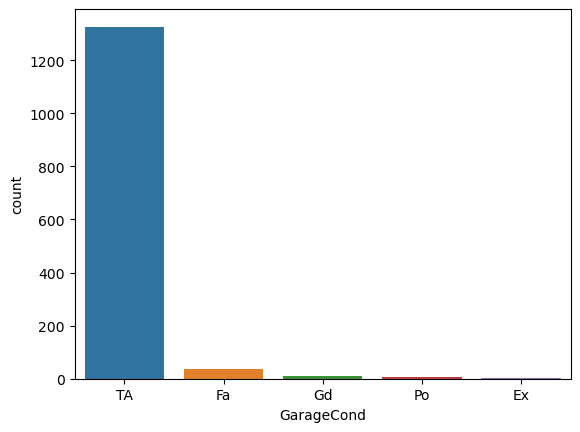

In [72]:
sns.countplot(data=data,x='GarageCond')

In [73]:
data['GarageCond'].mode()

0    TA
Name: GarageCond, dtype: object

In [74]:
data.loc[data['GarageCond'].isnull()==True,'GarageCond']='TA'

In [75]:
data.loc[data['GarageCond'].isnull()==True]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


## Handling missing values in GarageYrBlt

<AxesSubplot:xlabel='GarageYrBlt', ylabel='Count'>

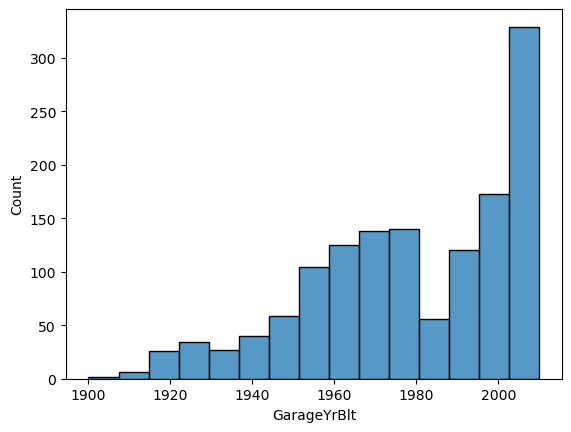

In [76]:
sns.histplot(data=data,x='GarageYrBlt')

In [77]:
data['GarageYrBlt'].median()

1980.0

In [78]:
data.loc[data['GarageYrBlt'].isnull()==True,'GarageYrBlt']=1980

In [79]:
data.loc[data['GarageYrBlt'].isnull()==True]

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice


In [80]:
#check for duplicated rows
data.duplicated().sum()

0

### label encoding

In [81]:
data1=data.copy()

In [82]:
cat_columns=data.select_dtypes(include='O').columns
cat_columns                   

Index(['MSZoning', 'Street', 'Alley', 'LotShape', 'LandContour', 'Utilities',
       'LotConfig', 'LandSlope', 'Neighborhood', 'Condition1', 'Condition2',
       'BldgType', 'HouseStyle', 'RoofStyle', 'RoofMatl', 'Exterior1st',
       'Exterior2nd', 'MasVnrType', 'ExterQual', 'ExterCond', 'Foundation',
       'BsmtQual', 'BsmtCond', 'BsmtExposure', 'BsmtFinType1', 'BsmtFinType2',
       'Heating', 'HeatingQC', 'CentralAir', 'Electrical', 'KitchenQual',
       'Functional', 'FireplaceQu', 'GarageType', 'GarageFinish', 'GarageQual',
       'GarageCond', 'PavedDrive', 'PoolQC', 'Fence', 'MiscFeature',
       'SaleType', 'SaleCondition'],
      dtype='object')

In [83]:
num_columns=data.select_dtypes(exclude='O').columns
num_columns

Index(['Id', 'MSSubClass', 'LotFrontage', 'LotArea', 'OverallQual',
       'OverallCond', 'YearBuilt', 'YearRemodAdd', 'MasVnrArea', 'BsmtFinSF1',
       'BsmtFinSF2', 'BsmtUnfSF', 'TotalBsmtSF', '1stFlrSF', '2ndFlrSF',
       'LowQualFinSF', 'GrLivArea', 'BsmtFullBath', 'BsmtHalfBath', 'FullBath',
       'HalfBath', 'BedroomAbvGr', 'KitchenAbvGr', 'TotRmsAbvGrd',
       'Fireplaces', 'GarageYrBlt', 'GarageCars', 'GarageArea', 'WoodDeckSF',
       'OpenPorchSF', 'EnclosedPorch', '3SsnPorch', 'ScreenPorch', 'PoolArea',
       'MiscVal', 'MoSold', 'YrSold', 'SalePrice'],
      dtype='object')

In [84]:
from sklearn.preprocessing import LabelEncoder
lc=LabelEncoder()

In [85]:
data1[cat_columns]=data1[cat_columns].apply(lc.fit_transform)

In [86]:
data1.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,3,65.0,8450,1,2,3,3,0,...,0,3,4,4,0,2,2008,8,4,208500
1,2,20,3,80.0,9600,1,2,3,3,0,...,0,3,4,4,0,5,2007,8,4,181500
2,3,60,3,68.0,11250,1,2,0,3,0,...,0,3,4,4,0,9,2008,8,4,223500
3,4,70,3,60.0,9550,1,2,0,3,0,...,0,3,4,4,0,2,2006,8,0,140000
4,5,60,3,84.0,14260,1,2,0,3,0,...,0,3,4,4,0,12,2008,8,4,250000


In [87]:
data.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [88]:
## Scaling

In [89]:
from sklearn.preprocessing import MinMaxScaler
scale=MinMaxScaler()

In [90]:
data1[['LotFrontage','LotArea','MasVnrArea','BsmtFinSF1','BsmtFinSF2','BsmtUnfSF','TotalBsmtSF','1stFlrSF','2ndFlrSF',
 'GrLivArea','GarageArea','WoodDeckSF','OpenPorchSF','EnclosedPorch','ScreenPorch',]]=scale.fit_transform(data1[['LotFrontage','LotArea','MasVnrArea','BsmtFinSF1','BsmtFinSF2','BsmtUnfSF','TotalBsmtSF','1stFlrSF','2ndFlrSF',
 'GrLivArea','GarageArea','WoodDeckSF','OpenPorchSF','EnclosedPorch','ScreenPorch']])

In [91]:
#checking the duplicated rows
data.duplicated().sum()

0

In [92]:
## Saving the preprocessed data
data1.to_csv('Preprocessed_data.csv')

In [93]:
# Loading data
Preprocessed_data=pd.read_csv('Preprocessed_data.csv')
Preprocessed_data

,Unnamed: 0,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,0,1,60,3,0.150685,0.033420,1,2,3,3,...,0,3,4,4,0,2,2008,8,4,208500
1,1,2,20,3,0.202055,0.038795,1,2,3,3,...,0,3,4,4,0,5,2007,8,4,181500
2,2,3,60,3,0.160959,0.046507,1,2,0,3,...,0,3,4,4,0,9,2008,8,4,223500
3,3,4,70,3,0.133562,0.038561,1,2,0,3,...,0,3,4,4,0,2,2006,8,0,140000
4,4,5,60,3,0.215753,0.060576,1,2,0,3,...,0,3,4,4,0,12,2008,8,4,250000
5,5,6,50,3,0.219178,0.059899,1,2,0,3,...,0,3,2,2,700,10,2009,8,4,143000
6,6,7,20,3,0.184932,0.041057,1,2,3,3,...,0,3,4,4,0,8,2007,8,4,307000
7,7,8,60,3,0.164384,0.042450,1,2,0,3,...,0,3,4,2,350,11,2009,8,4,200000
8,8,9,50,4,0.102740,0.022529,1,2,3,3,...,0,3,4,4,0,4,2008,8,0,129900
9,9,10,190,3,0.099315,0.028605,1,2,3,3,...,0,3,4,4,0,1,2008,8,4,118000


In [94]:
##Feature engineering
## dropping irrelevant column
Preprocessed_data.drop(['Unnamed: 0','Id','Alley','PoolQC','Fence', 'MiscFeature'],axis=1,inplace=True)

In [95]:
Preprocessed_data

,MSSubClass,MSZoning,LotFrontage,LotArea,Street,LotShape,LandContour,Utilities,LotConfig,LandSlope,...,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,3,0.150685,0.033420,1,3,3,0,4,0,...,0.000000,0,0.000000,0,0,2,2008,8,4,208500
1,20,3,0.202055,0.038795,1,3,3,0,2,0,...,0.000000,0,0.000000,0,0,5,2007,8,4,181500
2,60,3,0.160959,0.046507,1,0,3,0,4,0,...,0.000000,0,0.000000,0,0,9,2008,8,4,223500
3,70,3,0.133562,0.038561,1,0,3,0,0,0,...,0.492754,0,0.000000,0,0,2,2006,8,0,140000
4,60,3,0.215753,0.060576,1,0,3,0,2,0,...,0.000000,0,0.000000,0,0,12,2008,8,4,250000
5,50,3,0.219178,0.059899,1,0,3,0,4,0,...,0.000000,320,0.000000,0,700,10,2009,8,4,143000
6,20,3,0.184932,0.041057,1,3,3,0,4,0,...,0.000000,0,0.000000,0,0,8,2007,8,4,307000
7,60,3,0.164384,0.042450,1,0,3,0,0,0,...,0.413043,0,0.000000,0,350,11,2009,8,4,200000
8,50,4,0.102740,0.022529,1,3,3,0,4,0,...,0.371377,0,0.000000,0,0,4,2008,8,0,129900
9,190,3,0.099315,0.028605,1,3,3,0,0,0,...,0.000000,0,0.000000,0,0,1,2008,8,4,118000


In [96]:
Preprocessed_data.shape

(1460, 76)

In [97]:
## Temporal variables(date time variables)
for feature in ['YearBuilt', 'YearRemodAdd','GarageYrBlt']:
     Preprocessed_data[feature]=Preprocessed_data['YrSold']-Preprocessed_data[feature]

In [98]:
Preprocessed_data[['YearBuilt', 'YearRemodAdd','GarageYrBlt']].head()

,YearBuilt,YearRemodAdd,GarageYrBlt
0,5,5,5.0
1,31,31,31.0
2,7,6,7.0
3,91,36,8.0
4,8,8,8.0


<AxesSubplot:>

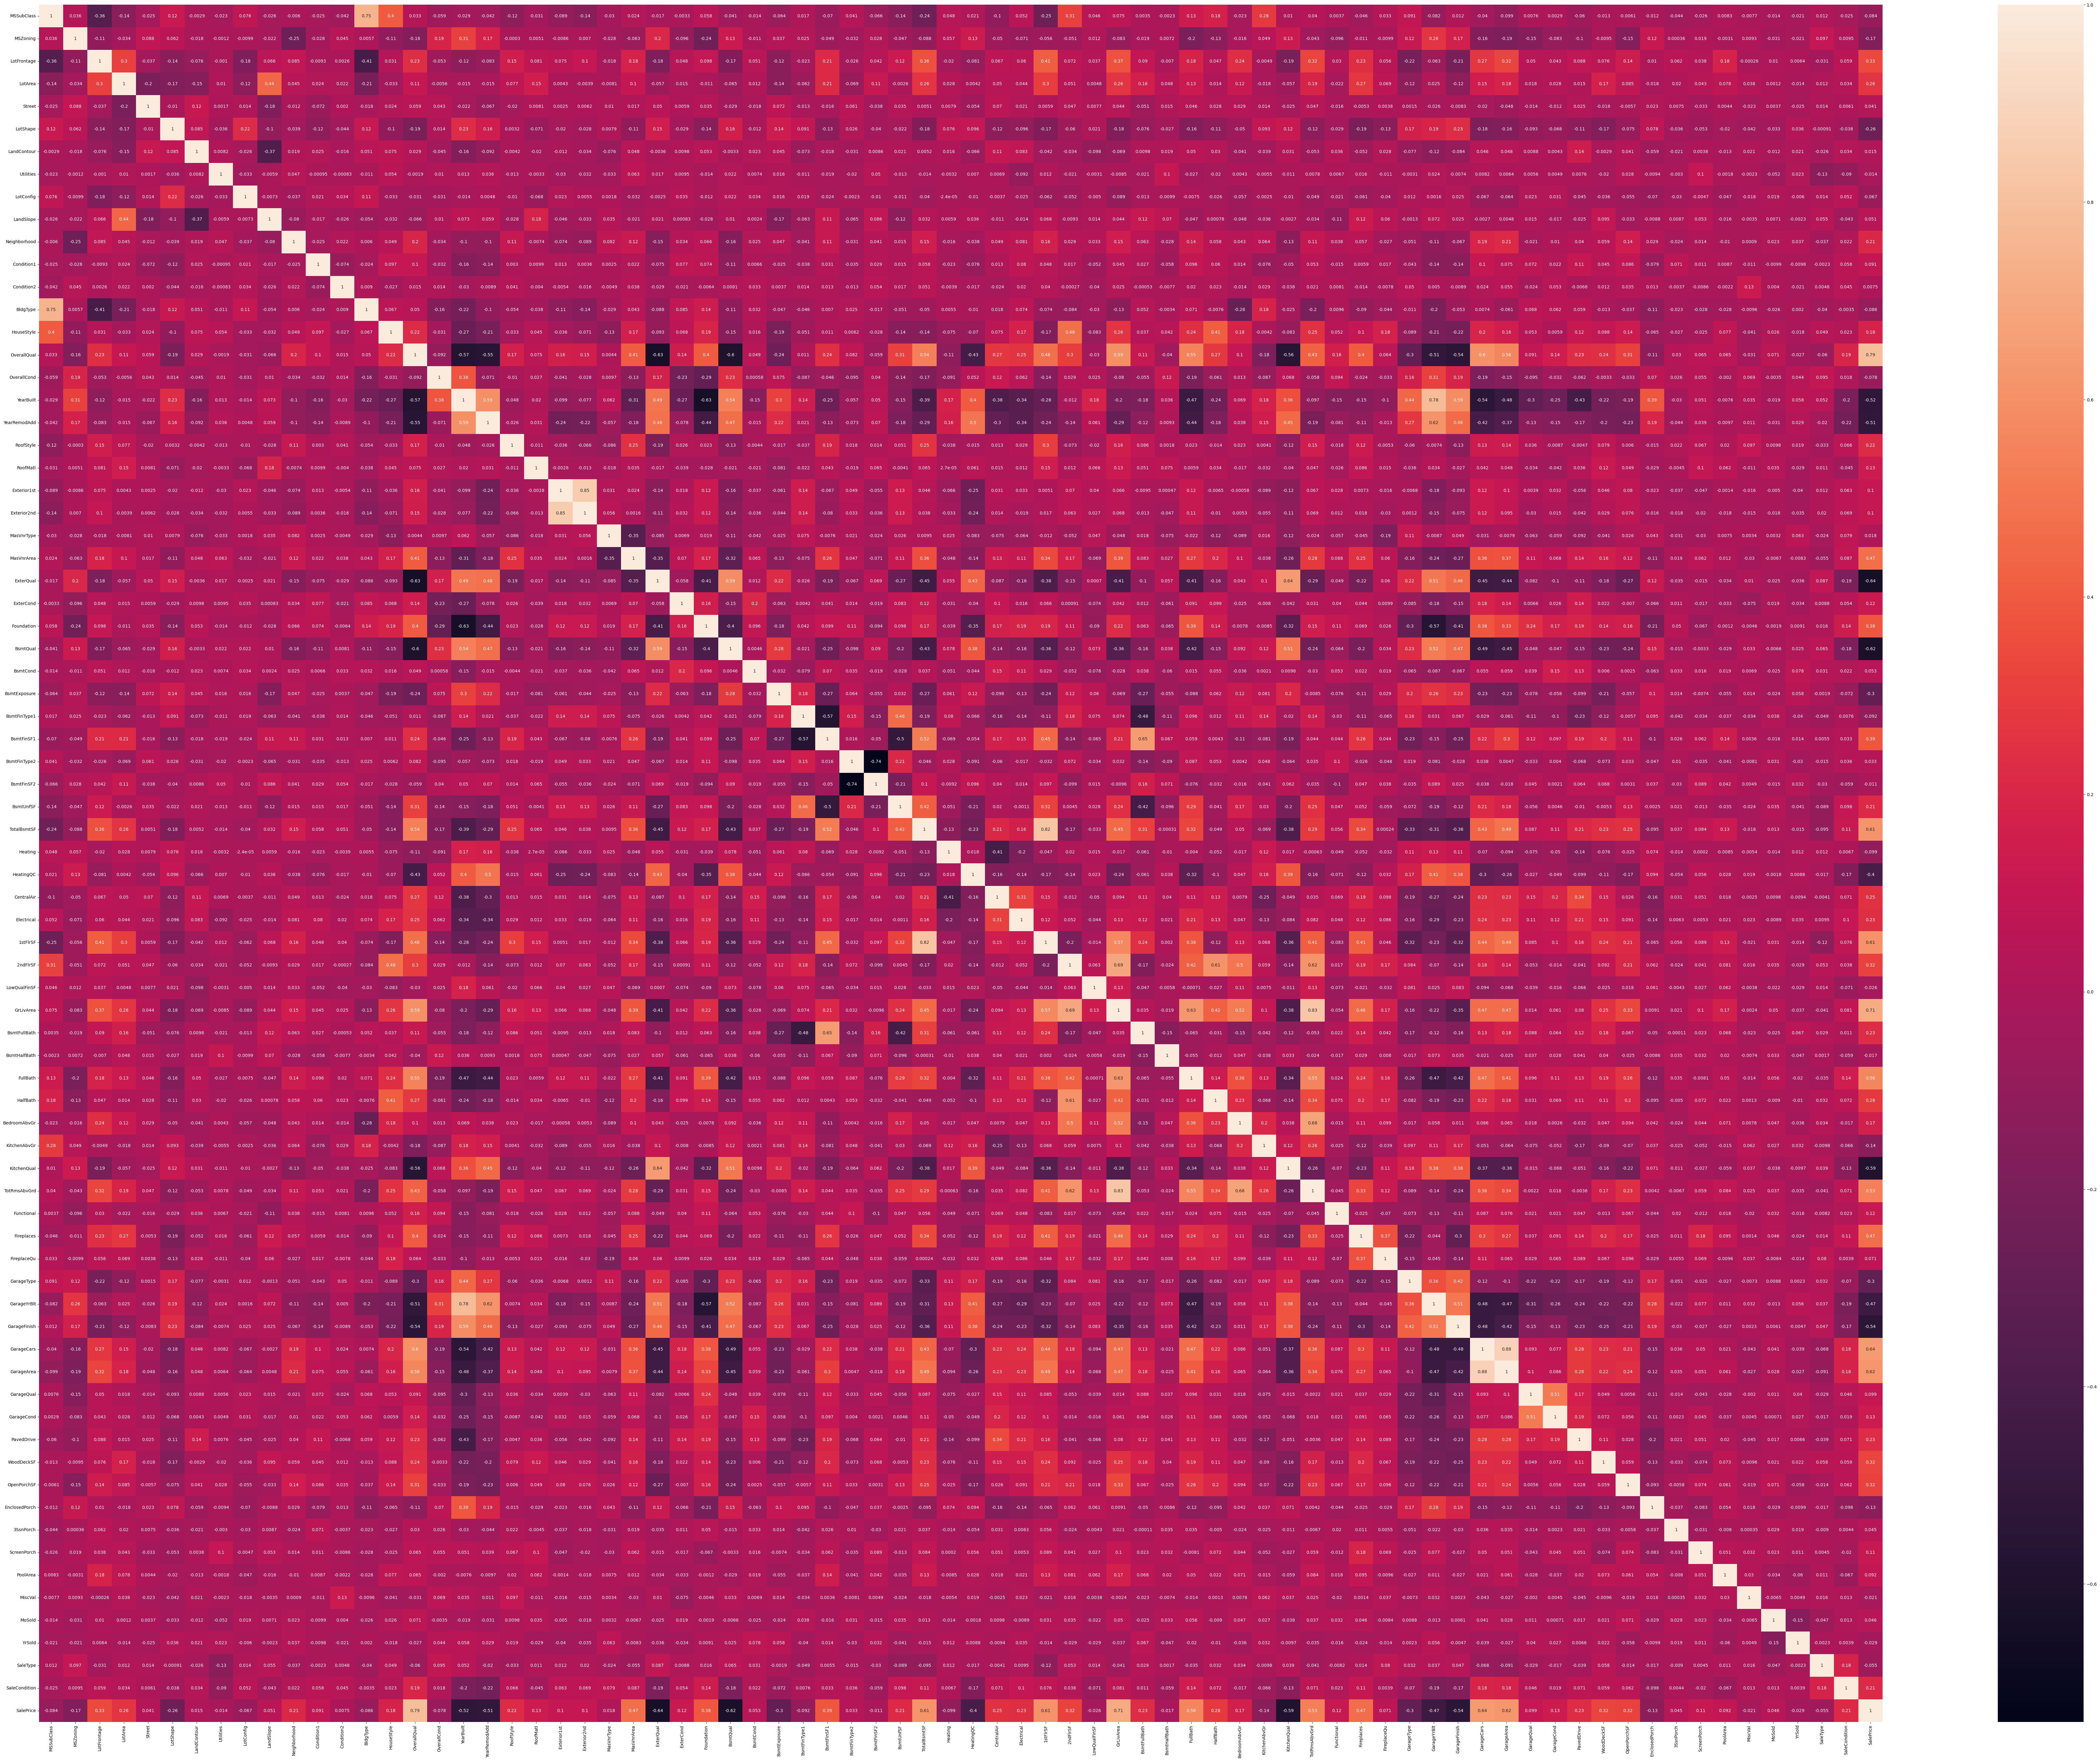

In [99]:
## checking correlation
fig=plt.gcf()
figsize=fig.get_size_inches()
fig.set_size_inches(figsize*15)
sns.heatmap(Preprocessed_data.corr(),annot=True)

In [100]:
#Dropping Highly Correlated variable
Preprocessed_data.drop(['GarageArea','Exterior1st'],axis=1,inplace=True)

In [101]:
Preprocessed_data.isnull().sum()

MSSubClass       0
MSZoning         0
LotFrontage      0
LotArea          0
Street           0
LotShape         0
LandContour      0
Utilities        0
LotConfig        0
LandSlope        0
Neighborhood     0
Condition1       0
Condition2       0
BldgType         0
HouseStyle       0
OverallQual      0
OverallCond      0
YearBuilt        0
YearRemodAdd     0
RoofStyle        0
RoofMatl         0
Exterior2nd      0
MasVnrType       0
MasVnrArea       0
ExterQual        0
ExterCond        0
Foundation       0
BsmtQual         0
BsmtCond         0
BsmtExposure     0
BsmtFinType1     0
BsmtFinSF1       0
BsmtFinType2     0
BsmtFinSF2       0
BsmtUnfSF        0
TotalBsmtSF      0
Heating          0
HeatingQC        0
CentralAir       0
Electrical       0
1stFlrSF         0
2ndFlrSF         0
LowQualFinSF     0
GrLivArea        0
BsmtFullBath     0
BsmtHalfBath     0
FullBath         0
HalfBath         0
BedroomAbvGr     0
KitchenAbvGr     0
KitchenQual      0
TotRmsAbvGrd     0
Functional  

# Insights

. cleaning and preprocessing the data to remove missing values, outliers, and other inconsistencies can improve the accuracy of   the model.

. There are no outliers

. # Scaling -->  Min max scaler

. # Convert catergorical data into numerical  --> Label encoder

. selecting the right set of features that have a significant impact on the house price is the primary step for accurate          prediction. The features may include 'LotFrontage','LotArea','MasVnrArea','BsmtFinSF1'...ect

. Heat map benifites --> 1) What is the correlation b/w x and y?
                       >  x Should be highly correlated with y.
                       2) No or little multi correlation.
                       >  There should not be high correlation among independent variables.
      ----> Clearly from this heat map we can conclude that there is no high correlation among independent variable
      
. To Balance the data and to get good accuracy we have droped this columns: 'Unnamed: 0','Id','Alley','PoolQC','Fence', 'MiscFeature' 

. In Feature Engineering:Creating new features that better capture the relationship between various input features and the target variable can help improve the accuracy of the model.

# Build model

In [102]:
# split data into x and y
x=Preprocessed_data.drop('SalePrice',axis=1)
Y=Preprocessed_data.SalePrice

In [103]:
#log transformation
y=np.log(Y)

In [104]:
# training and testing data
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=.2,random_state=3)

In [105]:
print('x_train',x_train.shape)
print('x_test',x_test.shape)
print('y_train',y_train.shape)
print('y_test',y_test.shape)

x_train (1168, 73)
x_test (292, 73)
y_train (1168,)
y_test (292,)


## XG Boost

In [122]:
## Installing XGB library
!pip3 install xgboost

In [123]:
import xgboost

In [124]:
## model creation
from xgboost import XGBRegressor
xgb_r=XGBRegressor() 
xgb_r.fit(x_train,y_train)
y_hat=xgb_r.predict(x_test)

In [125]:
### Hyper parameter tuning

In [126]:
from sklearn.model_selection import GridSearchCV
import xgboost as xgb

# Define the XGBoost model
xgb_model = xgb.XGBRegressor()

In [127]:
# Define the hyperparameters to tune
params = {
    "learning_rate": [0.05, 0.1, 0.15],
    "max_depth": [3, 5, 7],
    "subsample": [0.5, 0.7],
    "colsample_bytree": [0.5, 0.7],
    "n_estimators": [100, 500, 1000],
}

In [128]:
# Define the grid search object
grid_search = GridSearchCV(
    estimator=xgb_model,
    param_grid=params,
    cv=5,
    scoring="neg_mean_squared_error",
    n_jobs=-1,
)

In [129]:
# Fit the grid search object to the data
grid_search.fit(x, y)

# Print the best hyperparameters and the corresponding score
print(f"Best Hyperparameters: {grid_search.best_params_}")
print(f"Best Score: {grid_search.best_score_}")

Best Hyperparameters: {'colsample_bytree': 0.5, 'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 1000, 'subsample': 0.7}
Best Score: -0.015043344555738903


In [155]:
XGB=XGBRegressor(colsample_bytree= 0.5, learning_rate= 0.05, max_depth= 3, n_estimators= 1000, subsample= 0.7)

In [156]:
XGB.fit(x_train,y_train)#training
y_hat=XGB.predict(x_test)#testing

In [157]:
## EVALUATION

In [158]:
r2_score(y_test,y_hat)

0.8965367515133866

In [159]:
adj=1-(1-0.89)*(292-1)/(292-74-1)
adj

0.8524884792626728

## Insights

. Selecting the right machine learning algorithm that fits the data and the prediction problem is crucial. Linear regression, decision trees, Lasso regression,Hyperparameter Tuning and XGBoost algorithms we used for house price prediction.

. Among these algorithms XGBoost got best accuracy of 89% and rest all algorithms got below 85%.

. So we choosed XGBoost as a best algorithm for the house price prediction.